<a href="https://colab.research.google.com/github/pratham-239/UCS420/blob/main/Cognitive_Lab7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170190        # <-- your full roll number
NAME = "Pratham"           # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170190   Name: Pratham   Fingerprint: 8FB282F0   Tickets: 12

Ticket_ID                                                                 Ticket_Text
      T01                       The server is not working. Is there another solution?
      T02                  The password is running slowly. Is there another solution?
      T03                              The server crashes while opening. Please help.
      T04         I can't open the server after the latest update. Please resolve it.
      T05                                       Nothing works and nobody has replied.
      T06                              Re-installing didn't help; log-in still fails!
      T07 I am unable to use the password on my laptop. It works on another computer.
      T08                                                 The file is 95.5% uploaded.
      T09                      The VPN stopped responding. Is there another solution?
      T10                  E-mail was working yesterday since

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:

processed = {}
rows = []

for index, ticket in df.iterrows():
    result = process_ticket(ticket["Ticket_Text"])
    processed[ticket["Ticket_ID"]] = result

    rows.append({
        "Ticket_ID": ticket["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

result_df = pd.DataFrame(rows)

total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": result_df["Sentences"].sum(),
    "Tokens": result_df["Tokens"].sum(),
    "Punctuation Tokens": result_df["Punctuation Tokens"].sum(),
    "Stopwords": result_df["Stopwords"].sum(),
    "Unique Tokens": result_df["Unique Tokens"].sum(),
    "Final Tokens": result_df["Final Tokens"].sum()
}

result_df.loc[len(result_df)] = total_row

display(result_df)

selected_id = FOCUS[0]
selected_result = processed[selected_id]

print("Selected Ticket:", selected_id)
print("Ticket Text:", df.loc[df["Ticket_ID"] == selected_id, "Ticket_Text"].values[0])
print("Actual Tokens:", selected_result["tokens"])
print("Punctuation Tokens:", selected_result["punct"])
print("Stopwords:", selected_result["stops"])
print("Final Tokens:", selected_result["final"])


,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,11,2,5,10,4
1,T02,2,11,2,4,10,5
2,T03,2,9,2,2,8,5
3,T04,2,15,2,5,13,8
4,T05,1,7,1,2,7,4
5,T06,1,9,2,1,9,6
6,T07,2,17,2,8,15,7
7,T08,1,7,2,2,7,3
8,T09,2,10,2,3,10,5
9,T10,2,10,2,1,8,7


Selected Ticket: T01
Ticket Text: The server is not working. Is there another solution?
Actual Tokens: ['the', 'server', 'is', 'not', 'working', '.', 'is', 'there', 'another', 'solution', '?']
Punctuation Tokens: ['.', '?']
Stopwords: ['the', 'is', 'not', 'is', 'there']
Final Tokens: ['server', 'working', 'another', 'solution']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*  Some final tokens such as 'n't', 's and ca are not complete words. They come from contractions in the original tickets. NLTK's word_tokenize() separates contractions into smaller tokens. For example, "can't" may be split into ca and n't, while "it's" may be split into it and 's.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [10]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]


import re

long_words = r"\b[A-Za-z]{6,}\b"
numbers = r"\b\d+(?:,\d{3})*(?:\.\d+)*\b"
capitalized = r"\b[A-Z][a-zA-Z]*(?:[-'][A-Za-z]+)*\b"
vowel_words = r"\b[aeiou][a-z]*\b"

for index, ticket in df.iterrows():
    text = ticket["Ticket_Text"]

    print("\n", ticket["Ticket_ID"])
    print("Long Words:", re.findall(long_words, text))
    print("Numbers:", re.findall(numbers, text))
    print("Capitalized Words:", re.findall(capitalized, text))
    print("Words Starting with Vowel:", re.findall(vowel_words, text, re.IGNORECASE))

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"https?://[^\s<>]+?(?=[.,!?;:]?(?:\s|$))|www\.[^\s<>]+?(?=[.,!?;:]?(?:\s|$))"
phone_pattern = r"(?<!\w)(?:\+\d{1,3}[- ]?)?\d{3,5}[- ]\d{3,5}(?:[- ]\d{3,5})?(?!\w)"

def replace_patterns(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("\nREPLACEMENT ON TEST LINES")

for line in TEST_LINES:
    print(replace_patterns(line))

print("\nREPLACEMENT ON RAW TICKETS")

for index, ticket in df.iterrows():
    print(ticket["Ticket_ID"], ":", replace_patterns(ticket["Ticket_Text"]))



 T01
Long Words: ['server', 'working', 'another', 'solution']
Numbers: []
Capitalized Words: ['The', 'Is']
Words Starting with Vowel: ['is', 'Is', 'another']

 T02
Long Words: ['password', 'running', 'slowly', 'another', 'solution']
Numbers: []
Capitalized Words: ['The', 'Is']
Words Starting with Vowel: ['is', 'Is', 'another']

 T03
Long Words: ['server', 'crashes', 'opening', 'Please']
Numbers: []
Capitalized Words: ['The', 'Please']
Words Starting with Vowel: ['opening']

 T04
Long Words: ['server', 'latest', 'update', 'Please', 'resolve']
Numbers: []
Capitalized Words: ['I', 'Please']
Words Starting with Vowel: ['I', 'open', 'after', 'update', 'it']

 T05
Long Words: ['Nothing', 'nobody', 'replied']
Numbers: []
Capitalized Words: ['Nothing']
Words Starting with Vowel: ['and']

 T06
Long Words: ['installing']
Numbers: []
Capitalized Words: ['Re-installing']
Words Starting with Vowel: ['installing', 'in']

 T07
Long Words: ['unable', 'password', 'laptop', 'another', 'computer']
Numbe

In [11]:
count = 0

for index, ticket in df.iterrows():
    sentences = re.split(r"[.!?]+", ticket["Ticket_Text"])

    for sentence in sentences:
        words = re.findall(r"\b[A-Z][a-zA-Z]*\b", sentence.strip())

        if words:
            first_word = words[0]
            count += 1

print("Capitalized words at the start of sentences:", count)


Capitalized words at the start of sentences: 20


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*20

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [16]:

from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = r"""(?:[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|(?:https?://|www\.)[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+(?:/[A-Za-z0-9._~:/?#\[\]@!$&'()*+,;=%-]*[A-Za-z0-9_/#?&=%~-])?|(?<!\w)(?:\+\d{1,3}[ -]?)?\d{3,5}(?:[- ]\d{3,5}){1,2}(?!\w)|\d+(?:\.\d+)+|[A-Za-z0-9]+(?:-[A-Za-z0-9]+)+(?:['’][A-Za-z]+)?|[A-Za-z]+(?:['’][A-Za-z]+)?|[A-Za-z0-9]+|[^\w\s])"""

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

print("COMPARISON ON TEST_LINES")

for line in TEST_LINES:
    custom = my_tokenize(line)
    normal = word_tokenize(line)

    print("\nOriginal:", line)
    print("Custom Tokens:", custom)
    print("Word Tokens:", normal)
    print("Same:", custom == normal)

print("\nCOMPARISON ON TICKETS")

different_tickets = []

for index, ticket in df.iterrows():
    custom = my_tokenize(ticket["Ticket_Text"])
    normal = word_tokenize(ticket["Ticket_Text"])

    print("\nTicket:", ticket["Ticket_ID"])
    print("Custom Tokens:", custom)
    print("Word Tokens:", normal)
    print("Same:", custom == normal)

    if custom != normal:
        different_tickets.append(ticket["Ticket_ID"])

print("\nTickets tokenized differently:", different_tickets)
print("Number of different tickets:", len(different_tickets))
print("Total tickets:", len(df))


COMPARISON ON TEST_LINES

Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom Tokens: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
Word Tokens: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
Same: False

Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom Tokens: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
Word Tokens: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
Same: False

Original: The state-o

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* A total of 3 out of 12 tickets are tokenized differently by my_tokenize() and word_tokenize(). The different tickets are T04, T06 and T12.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [17]:

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
import pandas as pd

unique_tokens = sorted(set(
    token
    for ticket in df["Ticket_Text"]
    for token in process_ticket(ticket)["final"]
))

porter = PorterStemmer()
lancaster = LancasterStemmer()
regex = RegexpStemmer("ing$", min=4)
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("R"):
        return "r"
    else:
        return "n"

tagged_words = pos_tag(unique_tokens)

rows = []

for word, tag in tagged_words:
    porter_word = porter.stem(word)
    lancaster_word = lancaster.stem(word)
    regex_word = regex.stem(word)
    lemma_word = lemmatizer.lemmatize(word, get_wordnet_pos(tag))

    if len(set([porter_word, lancaster_word, regex_word, lemma_word])) > 1:
        rows.append({
            "Original Word": word,
            "Porter Stem": porter_word,
            "Lancaster Stem": lancaster_word,
            "Regexp Stem": regex_word,
            "WordNet Lemma": lemma_word
        })

result = pd.DataFrame(rows)

display(result)

print("Total unique final tokens:", len(unique_tokens))
print("Words with different outputs:", len(result))


,Original Word,Porter Stem,Lancaster Stem,Regexp Stem,WordNet Lemma
0,another,anoth,anoth,another,another
1,computer,comput,comput,computer,computer
2,crashes,crash,crash,crashes,crash
3,details,detail,detail,details,detail
4,fails,fail,fail,fails,fails
5,file,file,fil,file,file
6,https,http,https,https,https
7,latest,latest,latest,latest,late
8,mobile,mobil,mobl,mobile,mobile
9,nobody,nobodi,nobody,nobody,nobody


Total unique final tokens: 47
Words with different outputs: 32


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*
1. Over-stemming: server → serv using the Lancaster Stemmer. It removes too many characters and produces an incomplete stem that loses the original word's meaning.
2. Under-stemming: re-installing → re-install, while reinstalled remains reinstalled using the Regexp Stemmer. Both words are related to reinstall, but the ing$ rule removes only ing and does not handle ed.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,S1,S2,S3,S4
Total Tokens,127.0000,104.0000,64.0000,64.0000
Unique Tokens,72.0000,66.0000,47.0000,45.0000
TTR,0.5669,0.6346,0.7344,0.7031


Top 10 words in S1:
[('.', 16), ('the', 9), ('is', 7), ('another', 4), ('i', 4), ('server', 3), ('there', 3), ('solution', 3), ('?', 3), ('please', 3)]

Top 10 words in S3:
[('another', 4), ('server', 3), ('solution', 3), ('please', 3), ('help', 3), ('working', 2), ('password', 2), ("n't", 2), ('works', 2), ('use', 2)]


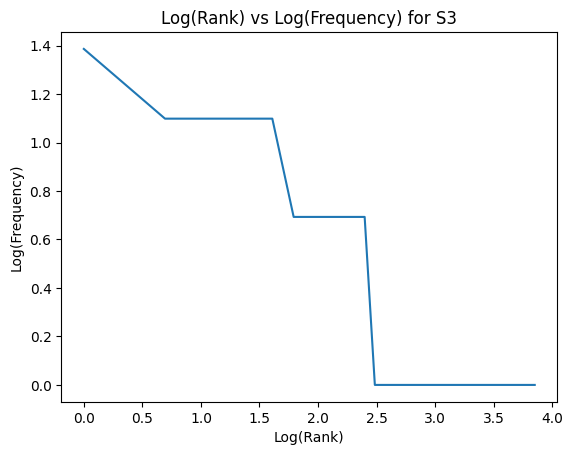


Top 5 bigrams in S1:
[(('the', 'server'), 3), (('.', 'is'), 3), (('is', 'there'), 3), (('there', 'another'), 3), (('another', 'solution'), 3)]

Top 5 bigrams in S3:
[(('another', 'solution'), 3), (('please', 'help'), 2), (('server', 'working'), 1), (('working', 'another'), 1), (('solution', 'password'), 1)]


In [18]:

from collections import Counter
from nltk.util import bigrams
from nltk.stem import PorterStemmer
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

S1 = []
S2 = []
S3 = []

for ticket in df["Ticket_Text"]:
    result = process_ticket(ticket)

    S1.extend(result["tokens"])
    S2.extend([t for t in result["tokens"] if not is_punct(t)])
    S3.extend(result["final"])

porter = PorterStemmer()
S4 = [porter.stem(t) for t in S3]

def corpus_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total > 0 else 0

    return {
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    }

stats = pd.DataFrame({
    "S1": corpus_stats(S1),
    "S2": corpus_stats(S2),
    "S3": corpus_stats(S3),
    "S4": corpus_stats(S4)
})

display(stats)

print("Top 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))

freq = Counter(S3).most_common()

ranks = range(1, len(freq) + 1)
frequencies = [item[1] for item in freq]

plt.plot(np.log(ranks), np.log(frequencies))
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.show()

print("\nTop 5 bigrams in S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams in S3:")
print(Counter(bigrams(S3)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*

The Type-Token Ratio (TTR) changes from S1 to S4 because each preprocessing step changes the number of total and unique tokens.

- **S1:** Contains all tokens, including punctuation and stopwords.
- **S2:** Punctuation is removed, reducing the total number of tokens.
- **S3:** Stopwords are also removed, leaving meaningful final tokens.
- **S4:** Porter stemming converts related words into common stems, which can reduce the number of unique tokens.

TTR is calculated as:

TTR = Unique Tokens / Total Tokens

Therefore, stemming generally reduces the number of unique tokens and can decrease TTR.

**Q6. Interpret:**

(a) Why does TTR change from S1 to S4 in your dataset?

TTR changes because preprocessing removes punctuation and stopwords, reducing the total number of tokens. Porter stemming also combines related words into common stems, reducing the number of unique tokens. Since both total and unique tokens change, the TTR changes.

(b) Give one example where word_tokenize() and your tokenizer differ.

For the word "isn't", word_tokenize() splits it into is and n't, whereas my custom tokenizer keeps it as one token. This happens because my regex pattern preserves contractions.

(c) Give one example where stemming produces an undesirable result.

The Lancaster Stemmer converts "server" into "serv". This is undesirable because the resulting stem is not a meaningful word and loses the original meaning.

(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

The word "was" is converted into "wa" by the Porter Stemmer, whereas POS-aware WordNet lemmatization converts it into "be". The lemma "be" is the correct base form of the verb and preserves its meaning better.